
# Тест 01: Supervised  learning (Обучение с учителем)

Этот тест предназначен для оценки ваших знаний об импорте данных, их визуализации и использовании моделей машинного обучения.
Пожалуйста, введите ответы непосредственно в ячейки, предназначенные для каждого раздела.


## 1. Импорт данных
    1. Импортируйте библиотеку `pandas` и загрузите файл `Human_Activity_Recognition_Using_Smartphones_Data.csv`.
    2. Проверьте размерности и типы данных.
    3. Выведите первые 5 строк DataFrame и проверьте наличие пропущенных значений.


In [50]:
import pandas as pd

features = pd.read_csv(
    "./UCI HAR Dataset/features.txt",
    sep=r"\s+",
    header=None,
    usecols=[1],
    names=["feature"]
)


X_train = pd.read_csv(
    "./UCI HAR Dataset/train/X_train.txt",
    sep=r"\s+",
    header=None
)

y_train = pd.read_csv(
    "./UCI HAR Dataset/train/y_train.txt",
    sep=r"\s+",
    header=None,
    names=["Activity"]
)


X_test = pd.read_csv(
    "./UCI HAR Dataset/test/X_test.txt",
    sep=r"\s+",
    header=None
)

y_test = pd.read_csv(
    "./UCI HAR Dataset/test/y_test.txt",
    sep=r"\s+",
    header=None,
    names=["Activity"]
)


X_train.columns = features["feature"]
X_test.columns = features["feature"]


train_df = X_train.join(y_train)
test_df = X_test.join(y_test)

df = pd.concat([train_df, test_df], ignore_index=True)

df.to_csv(
    "Human_Activity_Recognition_Using_Smartphones_Data.csv",
    index=False
)

print("Размер", df.shape)
print("\nТипы данных столбцов:")
print(df.dtypes)

display(df.head())

print("\nПроверка пропущенных значений:")
print("Всего пропущенных значений:", df.isnull().sum().sum())

Размер (10299, 562)

Типы данных столбцов:
tBodyAcc-mean()-X                       float64
tBodyAcc-mean()-Y                       float64
tBodyAcc-mean()-Z                       float64
tBodyAcc-std()-X                        float64
tBodyAcc-std()-Y                        float64
                                         ...   
angle(tBodyGyroJerkMean,gravityMean)    float64
angle(X,gravityMean)                    float64
angle(Y,gravityMean)                    float64
angle(Z,gravityMean)                    float64
Activity                                  int64
Length: 562, dtype: object


,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-skewness(),fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",Activity
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,...,-0.298676,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627,5
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,...,-0.595051,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317,5
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,...,-0.390748,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118,5
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,-0.989302,-0.938692,...,-0.117290,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663,5
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,-0.990441,-0.942469,...,-0.351471,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892,5



Проверка пропущенных значений:
Всего пропущенных значений: 0



## 2. Визуализация данных с помощью Matplotlib и Seaborn
1. Создайте точечную диаграмму (scatter plot) для отображения связи между двумя числовыми столбцами.
2. Используйте Seaborn для создания тепловой карты (heatmap) корреляций между столбцами.

1. Точечная диаграмма


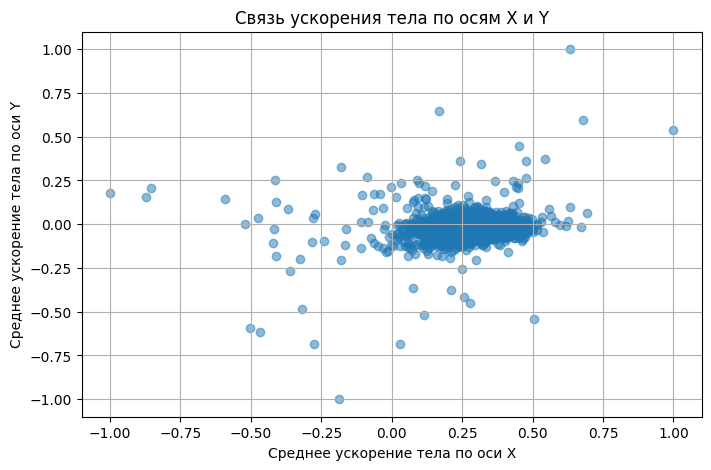

2. Тепловая карта корреляций


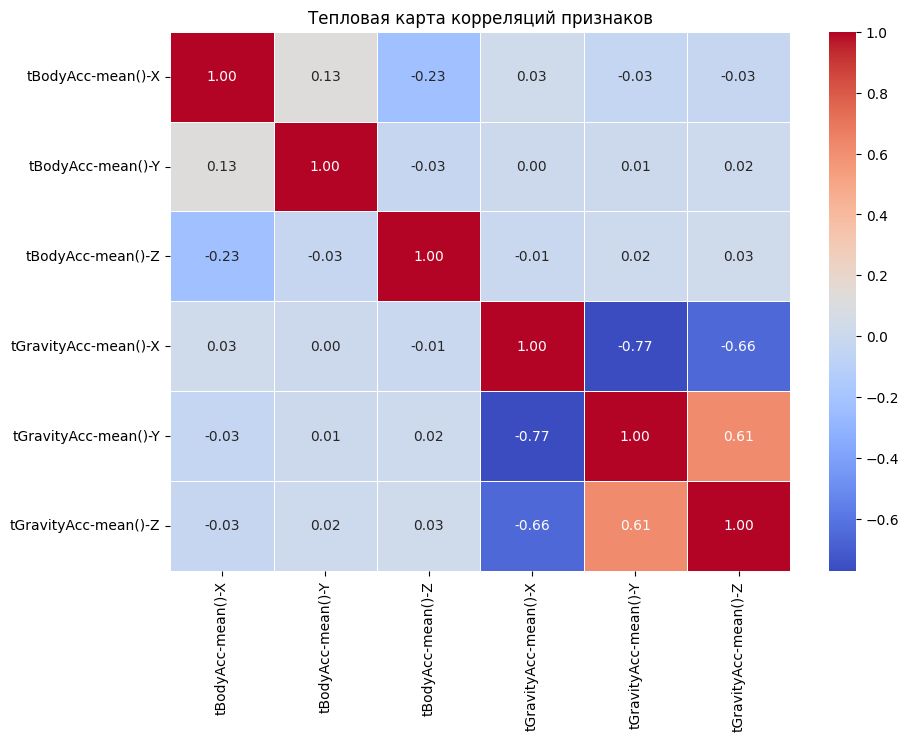

In [51]:
import matplotlib.pyplot as plt
import seaborn as sns

print("1. Точечная диаграмма")

plt.figure(figsize=(8, 5))

plt.scatter(
    df["tBodyAcc-mean()-X"],
    df["tBodyAcc-mean()-Y"],
    alpha=0.5
)

plt.xlabel("Среднее ускорение тела по оси X")
plt.ylabel("Среднее ускорение тела по оси Y")
plt.title("Связь ускорения тела по осям X и Y")
plt.grid(True)
plt.show()



print("2. Тепловая карта корреляций")

selected_columns = [
    "tBodyAcc-mean()-X",
    "tBodyAcc-mean()-Y",
    "tBodyAcc-mean()-Z",
    "tGravityAcc-mean()-X",
    "tGravityAcc-mean()-Y",
    "tGravityAcc-mean()-Z"
]

corr_matrix = df[selected_columns].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Тепловая карта корреляций признаков")
plt.show()

## 3. Метрики ошибки
1. Разделите набор данных на обучающую и тестовую выборки (80%-20%).
2. Постройте модель линейной регрессии на числовых данных.
3. Оцените производительность модели с использованием **MAE**, **MSE** и **RMSE**.


In [52]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

target_col = "tBodyAcc-mean()-X"
X_num = df.drop(columns=["Activity", target_col])
y_num = df[target_col]

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_num, y_num, test_size=0.2, random_state=42
)
print("Обучающая выборка:", Xr_train.shape)
print("Тестовая выборка:", Xr_test.shape)

lin_reg = LinearRegression()
lin_reg.fit(Xr_train, yr_train)
yr_pred = lin_reg.predict(Xr_test)

mae = mean_absolute_error(yr_test, yr_pred)
mse = mean_squared_error(yr_test, yr_pred)
rmse = np.sqrt(mse)

print("MAE :", round(mae, 4))
print("MSE :", round(mse, 6))
print("RMSE:", round(rmse, 4))

Обучающая выборка: (8239, 560)
Тестовая выборка: (2060, 560)
MAE : 0.0233
MSE : 0.001558
RMSE: 0.0395



## 4. Перекрёстная проверка (Cross Validation)
1. Импортируйте библиотеку `scikit-learn`.
2. Разделите набор данных на обучающую и тестовую выборки (80%-20%).
3. Используйте `cross_val_score` для оценки производительности модели KNN на наборе данных.


In [61]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import LabelEncoder

X = df.drop("Activity", axis=1)
le = LabelEncoder()
y = le.fit_transform(df["Activity"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

knn = KNeighborsClassifier(n_neighbors=5)

scores = cross_val_score(knn, X_train, y_train, cv=5)

print("Средняя точность:", round(scores.mean(), 4))

knn.fit(X_train, y_train)
print("Точность на тесте:", round(knn.score(X_test, y_test), 4))

Средняя точность: 0.9633
Точность на тесте: 0.9655



## 5. Модели машинного обучения
1. **Линейная регрессия**: Обучите модель линейной регрессии и оцените ее производительность на тестовой выборке.
2. **Логистическая регрессия**: Постройте логистическую модель для задачи бинарной классификации.
3. **SVM**: Обучите модель SVM и протестируйте ее на наборе данных.

In [ ]:
# 5.1 Линейная регрессия
lin_reg = LinearRegression()
lin_reg.fit(Xr_train, yr_train)
yr_pred = lin_reg.predict(Xr_test)

print("Линейная регрессия (цель: tBodyAcc-mean()-X)")
print("R2 :", round(r2_score(yr_test, yr_pred), 4))
print("MAE:", round(mean_absolute_error(yr_test, yr_pred), 4))
print("MSE:", round(mean_squared_error(yr_test, yr_pred), 6))

Линейная регрессия (цель: tBodyAcc-mean()-X)
R2 : 0.6858
MAE: 0.0233
MSE: 0.001558


In [ ]:
# 5.2 Логистическая регрессия
# 2 класса: 0 - движение (активности 1,2,3), 1 - покой (активности 4,5,6)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

y_bin = (df["Activity"] > 3).astype(int)

Xb_train, Xb_test, yb_train, yb_test = train_test_split(
    X, y_bin, test_size=0.2, random_state=42
)

log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(Xb_train, yb_train)
yb_pred = log_reg.predict(Xb_test)

print("Логистическая регрессия")
print("Точность:", round(accuracy_score(yb_test, yb_pred), 4))

Логистическая регрессия
Точность: 1.0


In [56]:
from sklearn.svm import SVC

svm = SVC(kernel="rbf")
svm.fit(X_train, y_train)
y_pred_svm = svm.predict(X_test)

print("SVM")
print("Точность:", round(accuracy_score(y_test, y_pred_svm), 4))

SVM
Точность: 0.9733


## 6. Матрица ошибок (Confusion Matrix)
1. Постройте модель логистической классификации.
2. Создайте матрицу ошибок и отобразите ее графически с помощью Seaborn.

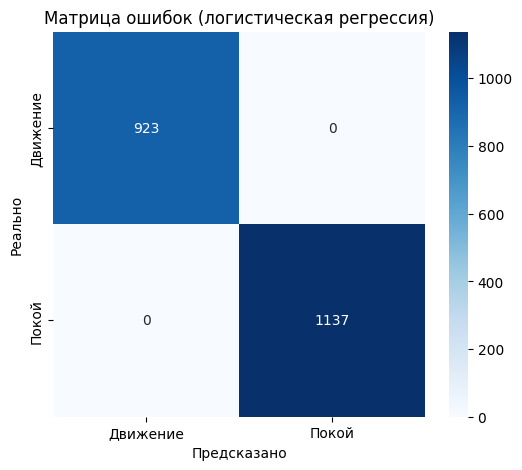

In [57]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(yb_test, yb_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Движение", "Покой"],
            yticklabels=["Движение", "Покой"])
plt.xlabel("Предсказано")
plt.ylabel("Реально")
plt.title("Матрица ошибок (логистическая регрессия)")
plt.show()


## 7. Градиентный спуск (Gradient Descent)
1. Реализуйте алгоритм градиентного спуска вручную для оптимизации заданной функции стоимости.
2. Используйте простую функцию $$J(\theta) = (\theta x - y)^2$$ на подмножестве данных.

Найденное theta: -0.05891
Итоговая стоимость: 0.00059246
Точное theta   : -0.05892


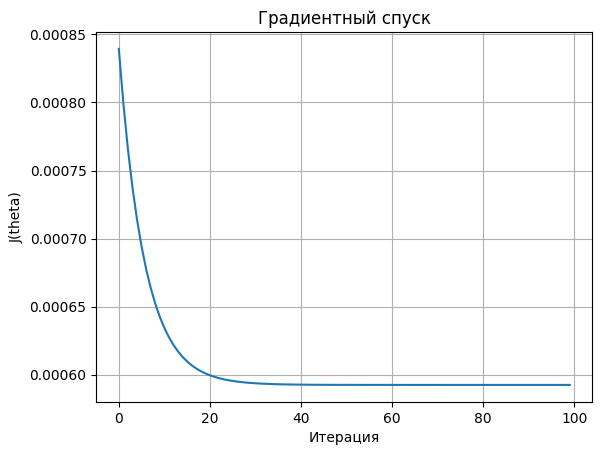

In [58]:
sub = df.sample(100, random_state=42)
x_g = sub["tBodyAcc-mean()-X"].values
y_g = sub["tBodyAcc-mean()-Y"].values

def cost(theta):
    return np.mean((theta * x_g - y_g) ** 2)

def gradient(theta):
    return 2 * np.mean(x_g * (theta * x_g - y_g))

theta = 0.0          
lr = 0.5             
epochs = 100
history = []

for i in range(epochs):
    theta = theta - lr * gradient(theta)
    history.append(cost(theta))

print("Найденное theta:", round(theta, 5))
print("Итоговая стоимость:", round(history[-1], 8))

theta_exact = np.sum(x_g * y_g) / np.sum(x_g ** 2)
print("Точное theta   :", round(theta_exact, 5))

plt.plot(history)
plt.xlabel("Итерация")
plt.ylabel("J(theta)")
plt.title("Градиентный спуск")
plt.grid(True)
plt.show()

## 8. Модели машинного обучения (part 2 - poate fi omis)
3. **Случайный лес (Random Forest)**: Используйте Random Forest для обучения модели и оцените важность признаков.
4. **Бустинг и бэггинг**: Сравните производительность моделей AdaBoost и Bagging.,


Random Forest точность: 0.9801

Топ-10 важных признаков:
tGravityAcc-mean()-X      0.040949
angle(X,gravityMean)      0.031466
tGravityAcc-max()-X       0.028701
tGravityAcc-energy()-X    0.026587
tGravityAcc-mean()-Y      0.024358
tGravityAcc-min()-X       0.022808
tGravityAcc-min()-Y       0.020831
tGravityAcc-max()-Y       0.019822
angle(Y,gravityMean)      0.017987
tBodyAccJerk-std()-X      0.014245
dtype: float64


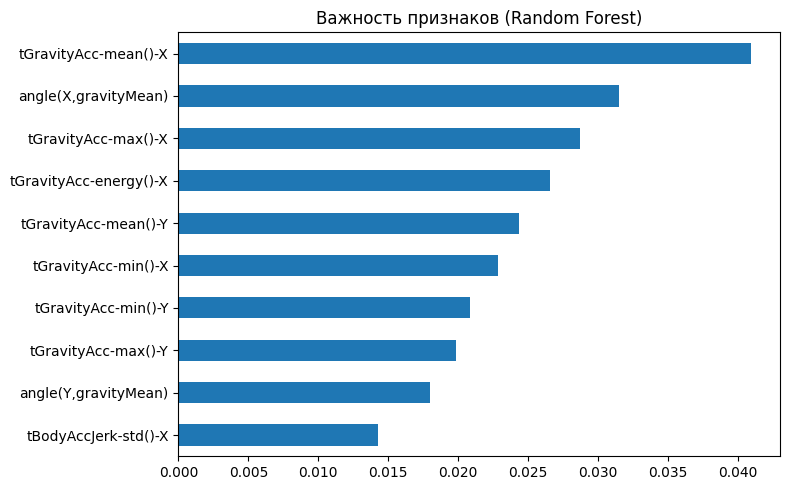

AdaBoost: 0.3519
Bagging: 0.9684


In [59]:
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, BaggingClassifier

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
print("Random Forest точность:", round(rf.score(X_test, y_test), 4))

importances = pd.Series(rf.feature_importances_, index=X.columns)
top10 = importances.sort_values(ascending=False).head(10)
print("\nТоп-10 важных признаков:")
print(top10)

plt.figure(figsize=(8, 5))
top10.sort_values().plot(kind="barh")
plt.title("Важность признаков (Random Forest)")
plt.tight_layout()
plt.show()


ada = AdaBoostClassifier(n_estimators=50, random_state=42)
bag = BaggingClassifier(n_estimators=50, random_state=42)

ada.fit(X_train, y_train)
bag.fit(X_train, y_train)

print("AdaBoost:", round(ada.score(X_test, y_test), 4))
print("Bagging:", round(bag.score(X_test, y_test), 4))

## 9. Стекинг (Stacking) (poate fi omis)
1. Постройте модель стекинга, используя Random Forest, SVM и логистическую регрессию в качестве базовых моделей.
2. Используйте модель логистической регрессии в качестве мета-модели.
3. Выведите итоговую точность на тестовой выборке.

In [60]:
from sklearn.ensemble import StackingClassifier, RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

base_models = [
    ("rf", RandomForestClassifier(n_estimators=50, random_state=42)),
    ("svm", SVC(probability=True, random_state=42))
]

meta_model = LogisticRegression(max_iter=1000)

stack = StackingClassifier(
    estimators=base_models,
    final_estimator=meta_model,
    cv=3
)

stack.fit(X_train, y_train)
y_pred_stack = stack.predict(X_test)

print("Точность стекинга на тесте:", round(accuracy_score(y_test, y_pred_stack), 4))

Точность стекинга на тесте: 0.9869



## Observații
Te rog, să salvezi  și să predai acest notebook după ce ai completat toate secțiunile.
